# Demo live – inferensi foto baru

Notebook ini untuk demo 10 menit. Yang biasanya diminta diubah ada di **pemanggilan fungsi** bagian 2 / 2b atau di sel
"Pengaturan", lalu jalankan ulang sel yang disebut di bawah ini.

| Permintaan | Ubah di sel Pengaturan | Jalankan ulang |
|---|---|---|
| Foto mycapture (ada ground truth) | nama file / nomor di baris terakhir bagian 2 | bagian 2 dan 3 |
| Foto baru tanpa anotasi | nama file di baris terakhir bagian 2b | bagian 2b saja |
| Threshold skor | `skor_min=` di pemanggilan fungsi, atau `SKOR_MIN` | sel itu saja (model tidak perlu dimuat ulang) |
| Model dengan data 25% / 50% | `run_label=` di pemanggilan fungsi, atau `RUN` | sel itu saja (model run lain dimuat otomatis) |
| AP satu kelas | `KELAS` | bagian 4 |

Foto baru **tidak punya anotasi**, jadi untuk foto itu hanya bisa dilihat hasil prediksinya, bukan AP.
AP selalu dihitung terhadap test set yang ada anotasinya (valid, test v5, mycapture).

In [19]:
import os, sys, time, warnings
warnings.filterwarnings("ignore")
os.environ["HF_HUB_OFFLINE"] = "1"      # config Mask2Former dibaca dari cache, jadi demo tetap jalan tanpa internet
sys.path.insert(0, os.path.abspath("lib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown
from common import load_json, mask_to_rle, coco_evaluate, gpu_name
import models as MD
import analysis as AN
AN.setup_style()
pd.set_option("display.precision", 3)

classes = load_json("mask2former/data_canonical/classes.json")    # 74 kelas v5, urutan sama dengan saat training
MODELS = list(AN.COLORS)                                          # yolo11s, maskrcnn, mask2former
print("device:", MD.DEVICE, "|", gpu_name(), "|", len(classes), "kelas")

device: cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU | 74 kelas


## Pengaturan

In [20]:
RUN = "100pct"                        # run bawaan: "025pct", "050pct", atau "100pct"
SKOR_MIN = 0.5                        # nilai bawaan skor_min: prediksi di bawah ini tidak ditampilkan
KELAS = "chair"                       # kelas untuk bagian 4 (harus salah satu dari 74 nama kelas v5)
SISI_PANJANG = 640                    # foto diperkecil dulu, sama dengan ukuran test set mycapture (640x480)
assert KELAS in classes, f"'{KELAS}' tidak ada. Contoh kelas: {classes[:10]}"

## 1. Memuat bobot hasil training

Bobot (`best.pt`) diambil dari hasil training di Kaggle. Ketiga model dimuat sekali dan tetap di GPU.
`score_thresh=0.05` dan `max_det=200` sama dengan saat evaluasi AP. Threshold tampilan (`skor_min`) diterapkan
belakangan, jadi mengubahnya tidak perlu memuat ulang model. Kalau fungsi demo dipanggil dengan `run_label` lain
(mis. `"025pct"`), model run itu dimuat otomatis sekali lalu disimpan di `MODEL_CACHE`.

In [21]:
t0 = time.time()
model = {k: MD.load_model(k, f"{k}/{RUN}", classes, score_thresh=0.05, max_det=200) for k in MODELS}
MODEL_CACHE = {RUN: model}
print(f"3 model ({RUN}) dimuat dalam {time.time() - t0:.0f} detik")

FONT_LABEL, FONT_JUDUL = 9, 14            # ukuran teks gambar demo


def ambil_model(run_label=None):
    run_label = run_label or RUN
    if run_label not in MODEL_CACHE:
        print(f"memuat model {run_label} ...")
        MODEL_CACHE[run_label] = {k: MD.load_model(k, f"{k}/{run_label}", classes, score_thresh=0.05, max_det=200)
                                  for k in MODELS}
    return MODEL_CACHE[run_label]


def prediksi(foto, mdl):
    # Inferensi ketiga model pada satu foto. Hasil: {model: [dict(category_id, score, area, segmentation RLE)]}
    det, waktu = {}, {}
    for k in MODELS:
        t0 = time.time()
        det[k] = []
        for d in mdl[k].predict_image(foto):
            m = d.pop("mask")                                       # mask biner seukuran foto
            det[k].append(dict(d, area=int(m.sum()), segmentation=mask_to_rle(m)))
        waktu[k] = time.time() - t0
    return det, waktu


def gambar_prediksi(ax, foto, det, skor_min, run_label):
    w, h = foto.size
    for a, k in zip(ax, MODELS):
        AN.overlay(foto, det[k], classes, h, w, score_thr=skor_min, ax=a, fontsize=FONT_LABEL)
        n = sum(d["score"] >= skor_min for d in det[k])
        a.set_title(f"{AN.LABELS[k]} ({run_label}): {n} objek, skor ≥ {skor_min}", fontsize=FONT_JUDUL)


def tabel_ringkas(det, skor_min, gt_anns=None):
    # Per kelas: jumlah objek GT (kalau ada) dan "jumlah (skor tertinggi)" tiap model
    rows = [{"model": AN.LABELS[k], "kelas": classes[d["category_id"] - 1], "skor": d["score"]}
            for k in MODELS for d in det[k] if d["score"] >= skor_min]
    cols = [AN.LABELS[k] for k in MODELS]
    t = (pd.DataFrame(rows, columns=["model", "kelas", "skor"]).groupby(["kelas", "model"]).skor
         .agg(lambda s: f"{len(s)} ({s.max():.2f})").unstack("model").reindex(columns=cols))
    judul = f"Kelas yang terdeteksi (skor ≥ {skor_min}): **jumlah objek (skor tertinggi)**"
    if gt_anns is not None:
        gt_n = pd.Series([classes[a["category_id"] - 1] for a in gt_anns if not a["iscrowd"]], dtype=object).value_counts()
        t = t.reindex(t.index.union(gt_n.index))
        t.insert(0, "Ground truth", gt_n.reindex(t.index).map(lambda v: "–" if pd.isna(v) else str(int(v))))
        judul += ". Kolom ground truth = jumlah objek di anotasi"
    t.index.name, t.columns.name = "kelas", None
    display(Markdown(judul))
    display(t.fillna("–"))

3 model (100pct) dimuat dalam 1 detik


## 2. Foto mycapture (ada ground truth)

Untuk foto test set sendiri yang sudah dianotasi. Cukup isi **nama file atau nomornya** di baris paling bawah sel ini,
mis. `demo_mycapture("mycapture_41.jpg")` atau `demo_mycapture(41)`. Threshold dan run bisa diubah langsung:
`demo_mycapture(55, skor_min=0.3, run_label="025pct")`.
Gambar yang dipakai adalah export Roboflow 640×480, sama persis dengan yang dievaluasi di notebook 05.

mycapture_49: 640x480 | ground truth 16 objek


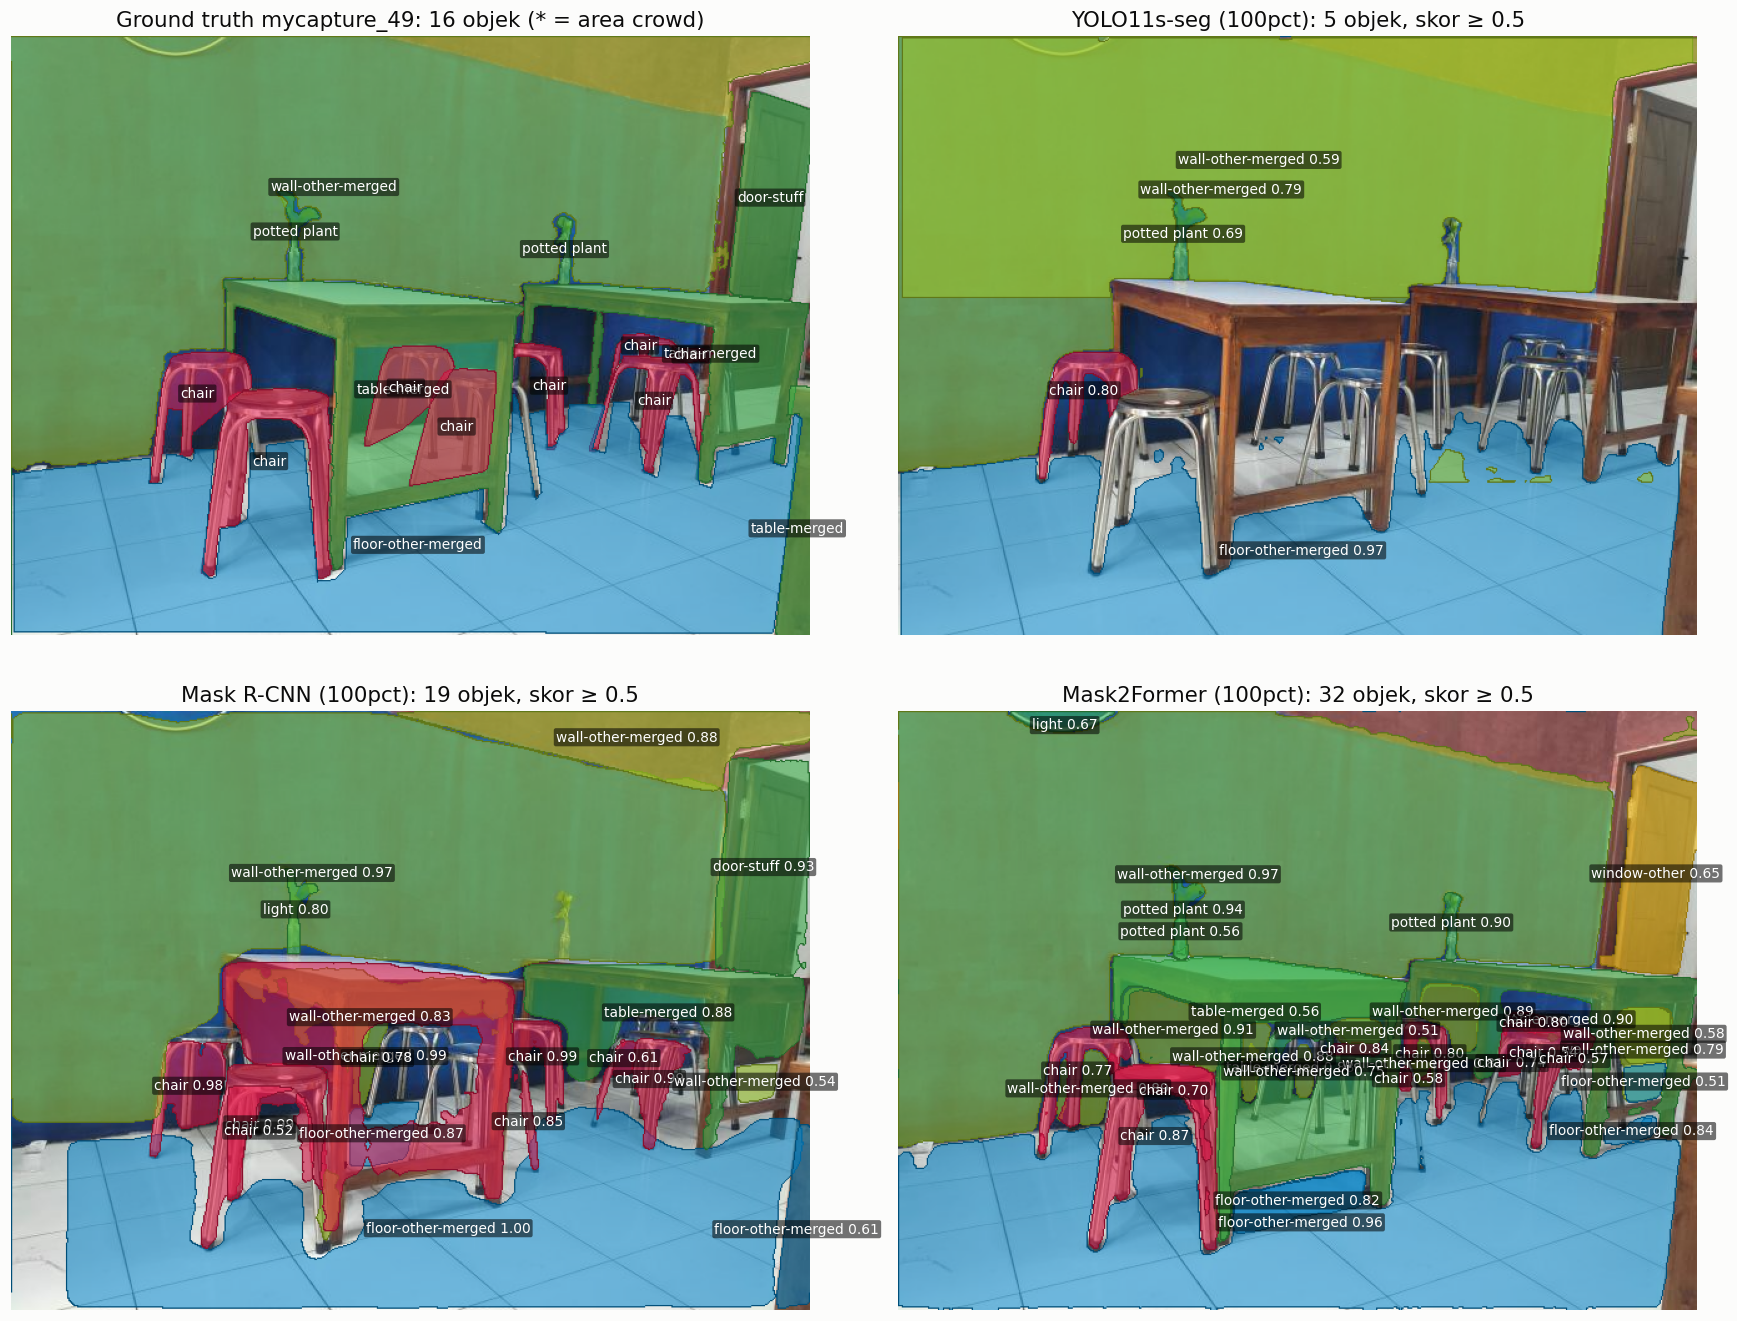

Kelas yang terdeteksi (skor ≥ 0.5): **jumlah objek (skor tertinggi)**. Kolom ground truth = jumlah objek di anotasi

,Ground truth,YOLO11s-seg,Mask R-CNN,Mask2Former
kelas,,,,
chair,8,1 (0.80),8 (0.99),10 (0.87)
door-stuff,1,–,1 (0.93),–
floor-other-merged,1,1 (0.97),3 (1.00),4 (0.96)
light,–,–,1 (0.80),1 (0.67)
potted plant,2,1 (0.69),–,3 (0.94)
table-merged,3,–,1 (0.88),3 (0.90)
wall-other-merged,1,2 (0.79),5 (0.99),10 (0.97)
window-other,–,–,–,1 (0.65)


In [43]:
GT_MC = "hasil_lokal/data/mycapture.json"
mc = load_json(GT_MC)
MC_BY_NO = {AN.photo_number(im["orig_file_name"]): im for im in mc["images"]}


def demo_mycapture(nama_file, skor_min=None, run_label=None):
    skor_min = SKOR_MIN if skor_min is None else skor_min
    run_label = run_label or RUN
    no = nama_file if isinstance(nama_file, int) else AN.photo_number(os.path.basename(str(nama_file)))
    if no is None and str(nama_file).isdigit():
        no = int(nama_file)
    if no not in MC_BY_NO:
        raise ValueError(f"'{nama_file}' bukan foto mycapture yang dianotasi. Nomor yang ada: {sorted(MC_BY_NO)}")
    im = MC_BY_NO[no]
    foto = Image.open(im["path"]).convert("RGB")
    g = [a for a in mc["annotations"] if a["image_id"] == im["id"]]
    det, waktu = prediksi(foto, ambil_model(run_label))
    print(f"mycapture_{no:02d}: {foto.size[0]}x{foto.size[1]} | ground truth {sum(not a['iscrowd'] for a in g)} objek")

    fig, axes = plt.subplots(2, 2, figsize=(16, 12.5))
    ax = axes.flat
    AN.overlay(foto, g, classes, im["height"], im["width"], ax=ax[0], fontsize=FONT_LABEL)
    ax[0].set_title(f"Ground truth mycapture_{no:02d}: {sum(not a['iscrowd'] for a in g)} objek (* = area crowd)",
                    fontsize=FONT_JUDUL)
    gambar_prediksi(ax[1:], foto, det, skor_min, run_label)
    fig.tight_layout(); plt.show()
    tabel_ringkas(det, skor_min, gt_anns=g)
    return det, waktu, foto.size


hasil, waktu, (W, H) = demo_mycapture("mycapture_49.jpg", skor_min=0.5, run_label="100pct")     # ganti nama file / nomor foto mycapture

## 2b. Foto baru tanpa anotasi

Untuk foto yang diambil saat demo. Simpan foto di folder `demo/`, lalu cukup ganti **nama file** di baris paling bawah
sel ini. Threshold dan run bisa diubah langsung: `demo_foto_baru("foto_baru.jpg", skor_min=0.3, run_label="025pct")`.
Karena foto ini belum dianotasi, yang bisa dilihat hanya prediksinya; AP tidak bisa dihitung.

mycapture/testdemo.png: 1280x960 -> 640x480


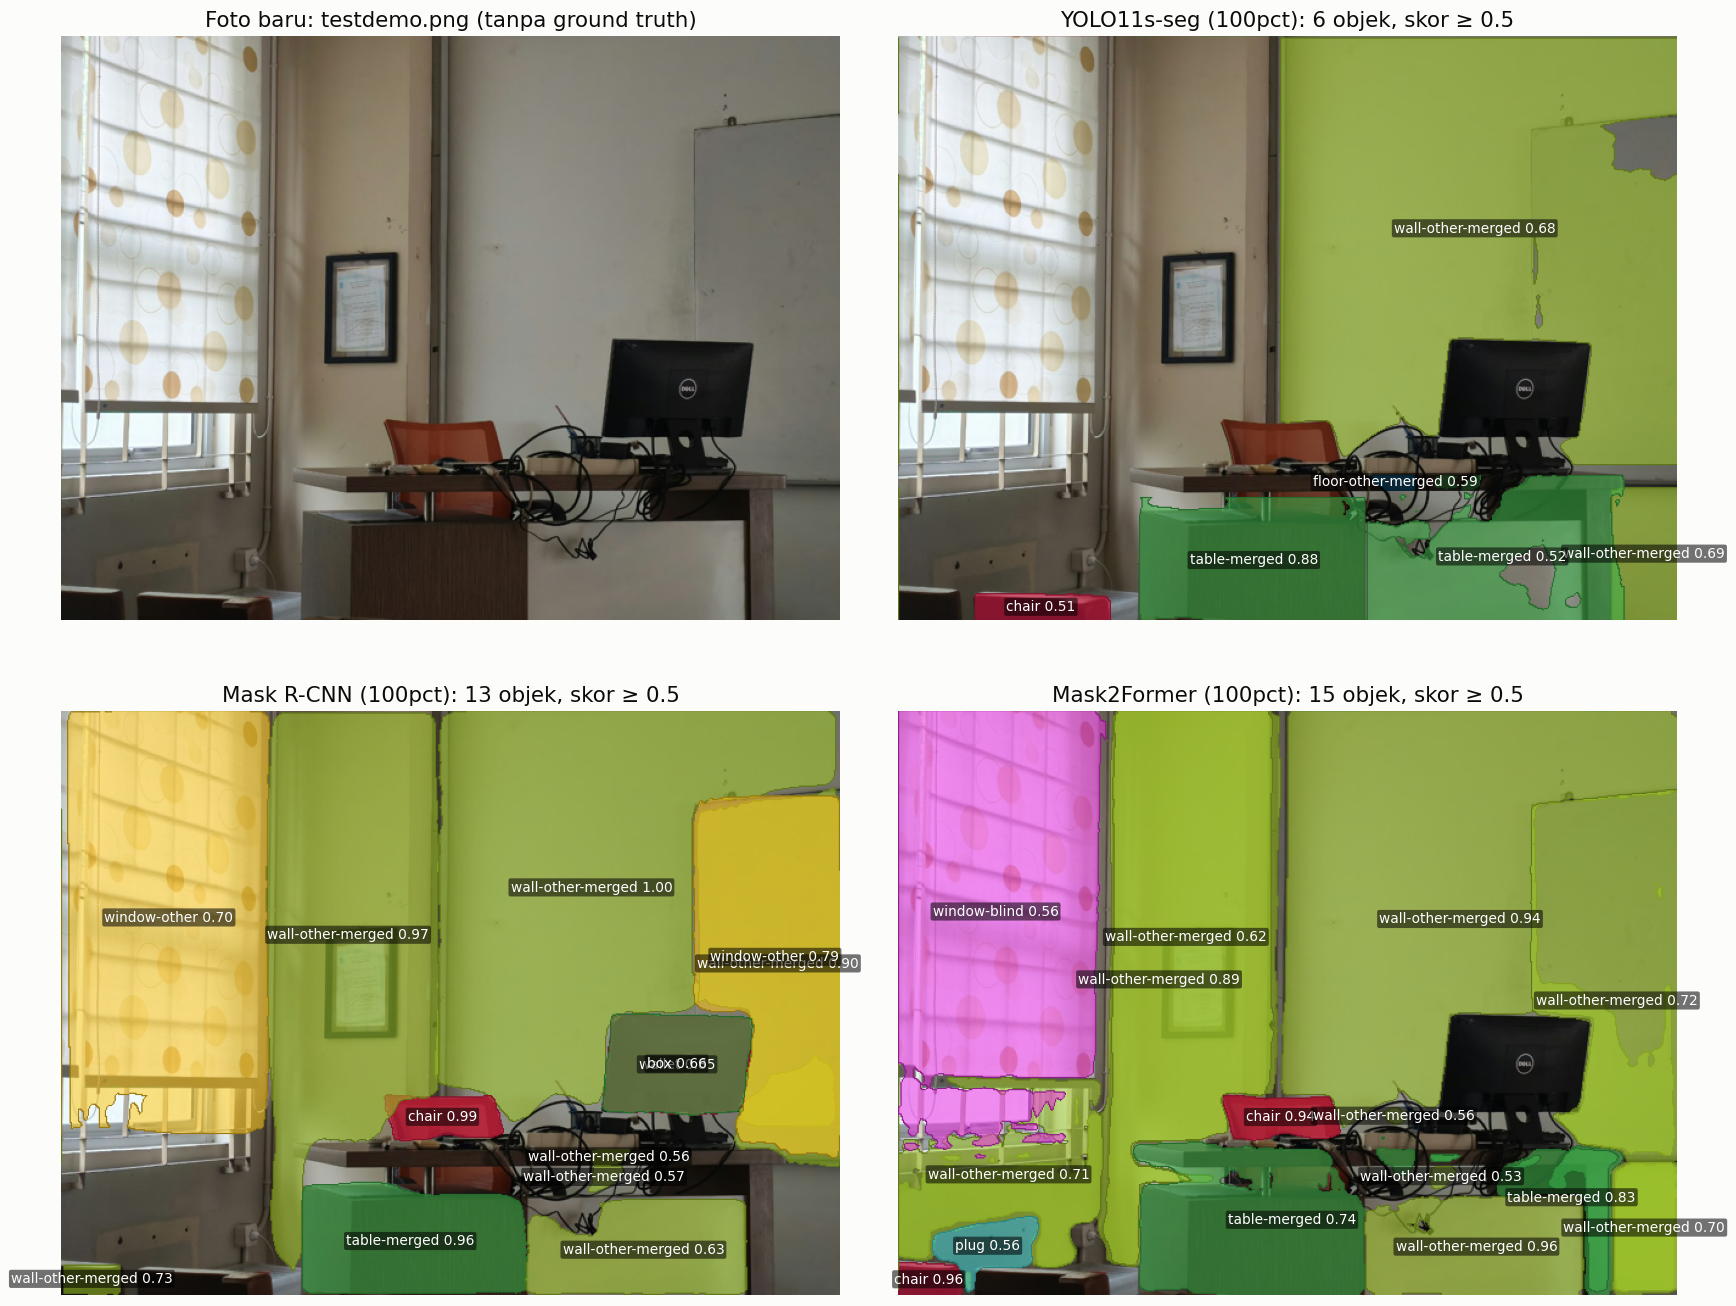

Kelas yang terdeteksi (skor ≥ 0.5): **jumlah objek (skor tertinggi)**

,YOLO11s-seg,Mask R-CNN,Mask2Former
kelas,,,
box,–,1 (0.66),–
chair,1 (0.51),1 (0.99),2 (0.96)
floor-other-merged,1 (0.59),–,–
plug,–,–,1 (0.56)
table-merged,2 (0.88),1 (0.96),2 (0.83)
wall-other-merged,2 (0.69),7 (1.00),9 (0.96)
wallet,–,1 (0.85),–
window-blind,–,–,1 (0.56)
window-other,–,2 (0.79),–


In [44]:
def demo_foto_baru(nama_file, skor_min=None, run_label=None):
    # nama_file dicari di folder demo/ (atau path lengkap)
    skor_min = SKOR_MIN if skor_min is None else skor_min
    run_label = run_label or RUN
    path = nama_file if os.path.exists(nama_file) else os.path.join("demo", nama_file)
    if not os.path.exists(path):
        ada = sorted(os.listdir("demo")) if os.path.isdir("demo") else []
        print(f"File '{nama_file}' tidak ditemukan. Simpan foto di folder demo/. Isi folder demo/: {ada}")
        return
    foto = ImageOps.exif_transpose(Image.open(path)).convert("RGB")      # putar sesuai EXIF HP
    asli = foto.size
    foto.thumbnail((SISI_PANJANG, SISI_PANJANG))                          # sisi panjang jadi 640, rasio tetap
    det, waktu = prediksi(foto, ambil_model(run_label))
    print(f"{path}: {asli[0]}x{asli[1]} -> {foto.size[0]}x{foto.size[1]}")

    fig, axes = plt.subplots(2, 2, figsize=(16, 12.5))
    ax = axes.flat
    ax[0].imshow(foto); ax[0].set_axis_off()
    ax[0].set_title(f"Foto baru: {os.path.basename(path)} (tanpa ground truth)", fontsize=FONT_JUDUL)
    gambar_prediksi(ax[1:], foto, det, skor_min, run_label)
    fig.tight_layout(); plt.show()
    tabel_ringkas(det, skor_min)
    return det


hasil_baru = demo_foto_baru("mycapture/testdemo.png", skor_min=0.5, run_label="100pct")

## 3. Daftar objek yang terdeteksi

In [24]:
rows = []
for k in MODELS:
    for d in hasil[k]:
        if d["score"] >= SKOR_MIN:
            rows.append({"model": AN.LABELS[k], "kelas": classes[d["category_id"] - 1], "skor": d["score"],
                         "luas (% foto)": 100 * d["area"] / (W * H)})
det = pd.DataFrame(rows, columns=["model", "kelas", "skor", "luas (% foto)"])
display(pd.DataFrame({AN.LABELS[k]: {"waktu inferensi (detik)": waktu[k],
                                     "prediksi skor ≥ 0.05": len(hasil[k]),
                                     f"prediksi skor ≥ {SKOR_MIN}": sum(d["score"] >= SKOR_MIN for d in hasil[k])}
                      for k in MODELS}).round(2))
det.sort_values(["model", "skor"], ascending=[True, False]).set_index(["model", "kelas"]).round(2)

,YOLO11s-seg,Mask R-CNN,Mask2Former
waktu inferensi (detik),0.21,0.27,0.32
prediksi skor ≥ 0.05,30.00,68.00,98.00
prediksi skor ≥ 0.5,4.00,10.00,16.00


skor  luas (% foto)
model       kelas                                  
Mask R-CNN  wall-brick          0.98          31.31
            bed                 0.87          12.83
            bottle              0.84           0.88
            potted plant        0.84           1.07
            wall-brick          0.82          23.04
            wall-other-merged   0.80           0.41
            chair               0.80           1.67
            floor-other-merged  0.79           0.66
            person              0.57           1.78
            potted plant        0.53           0.49
Mask2Former table-merged        0.92           1.95
            table-merged        0.79           1.51
            floor-wood          0.75           0.61
            wall-other-merged   0.73           2.19
            potted plant        0.69           0.85
            potted plant        0.65           0.38
            toy                 0.64           0.51
            wall-other-merged   0.62           0.77
            table-merged        0.61           2.63
            wall-other-merged   0.57           0.11
            wall-other-merged   0.57           0.85
            toy                 0.56           1.96
            wall-other-merged   0.55           1.22
            wall-other-merged   0.52           1.39
            potted plant        0.51           0.37
            toy                 0.51           0.68
YOLO11s-seg bottle              0.77           1.25
            bottle              0.77           0.90
            table-merged        0.72           1.87
            window-other        0.62           0.76

Pengaruh threshold: jumlah objek yang ditampilkan untuk beberapa nilai threshold sekaligus.

In [25]:
pd.DataFrame({AN.LABELS[k]: {f"skor ≥ {t}": sum(d["score"] >= t for d in hasil[k]) for t in (0.05, 0.3, 0.5, 0.7, 0.9)}
              for k in MODELS})

,YOLO11s-seg,Mask R-CNN,Mask2Former
skor ≥ 0.05,30,68,98
skor ≥ 0.3,10,19,25
skor ≥ 0.5,4,10,16
skor ≥ 0.7,3,8,4
skor ≥ 0.9,0,1,1


## 4. AP satu kelas

Mask AP kelas `KELAS` untuk ketiga model dan ketiga jumlah data latih:
- **valid** dan **test v5** dibaca dari hasil Kaggle (`<model>/<run>/per_class_AP_*.csv`);
- **mycapture** dihitung ulang dari prediksi yang tersimpan (`hasil_lokal/preds/`), dengan pycocotools.

Jumlah contoh kelas itu di data latih ikut ditampilkan, karena biasanya itulah penjelas utama angka AP-nya.

In [26]:
stats = pd.read_csv("outputs/class_stats_v5.csv").set_index("class")
GT_MC = "hasil_lokal/data/mycapture.json"
mc = load_json(GT_MC)
cid = classes.index(KELAS) + 1
n_mc = sum(a["category_id"] == cid and not a["iscrowd"] for a in mc["annotations"])
n = stats.loc[KELAS] if KELAS in stats.index else None
display(Markdown(f"**{KELAS}**: train v5 = {0 if n is None else int(n.instances_train)}, "
                 f"valid = {0 if n is None else int(n.instances_valid)}, test v5 = {0 if n is None else int(n.instances_test)}, "
                 f"mycapture = {n_mc} objek"))

rows = []
for k in MODELS:
    for t in AN.FRACS:
        r = {"model": AN.LABELS[k], "data": AN.FRAC_LABEL[t]}
        for split in ("valid", "test_v5"):
            f = pd.read_csv(f"{k}/{t}/per_class_AP_{split}.csv").set_index("class")["mask_AP"]
            r[split] = f.get(KELAS, np.nan)
        p = f"hasil_lokal/preds/{k}_{t}_mycapture.json"
        r["mycapture"] = coco_evaluate(GT_MC, load_json(p), 200)[1].get(KELAS, np.nan) if os.path.exists(p) else np.nan
        rows.append(r)
display(Markdown("Mask AP (kosong = kelas tidak ada di split itu):"))
pd.DataFrame(rows).set_index(["model", "data"]).round(3)

**chair**: train v5 = 217, valid = 67, test v5 = 353, mycapture = 104 objek

Mask AP (kosong = kelas tidak ada di split itu):

valid  test_v5  mycapture
model       data                           
YOLO11s-seg 25%   0.559    0.322      0.083
            50%   0.447    0.220      0.006
            100%  0.469    0.218      0.013
Mask R-CNN  25%   0.542    0.259      0.011
            50%   0.529    0.247      0.024
            100%  0.533    0.245      0.033
Mask2Former 25%   0.624    0.325      0.026
            50%   0.583    0.341      0.059
            100%  0.619    0.317      0.048

In [27]:
rows = {}
for k in MODELS:
    p = load_json(f"hasil_lokal/preds/{k}_{RUN}_mycapture.json")
    rows[AN.LABELS[k]] = {f"prediksi skor ≥ {t}": coco_evaluate(GT_MC, [d for d in p if d["score"] >= t], 200)[0]["AP"]
                          for t in (0.05, 0.3, 0.5, 0.7)}
display(Markdown(f"Mask AP mycapture ({RUN}) kalau prediksi difilter dulu dengan threshold:"))
pd.DataFrame(rows).round(3)

Mask AP mycapture (100pct) kalau prediksi difilter dulu dengan threshold:

,YOLO11s-seg,Mask R-CNN,Mask2Former
prediksi skor ≥ 0.05,0.070,0.090,0.140
prediksi skor ≥ 0.3,0.058,0.084,0.112
prediksi skor ≥ 0.5,0.049,0.070,0.100
prediksi skor ≥ 0.7,0.041,0.068,0.082
